# 03 - Implementasi: dari Scraping sampai Prediksi

Notebook ini memakai model hasil notebook 02 untuk menilai komentar baru dari YouTube.

**Cara memakai:**
1. Isi `VIDEO_IDS` pada sel di bawah. ID video adalah bagian setelah `watch?v=` pada URL YouTube.
2. Pilih `Run All`. Notebook berjalan sekali, lalu selesai.
3. Hasilnya ada di `outputs/hasil_prediksi.csv`.

**Alur:** scraping -> cleaning -> filter panjang -> buang duplikat -> vektorisasi -> prediksi 5 model -> CSV hasil

**Untuk laporan:** Tabel 3.1 - 3.7 dan Gambar 3.1; file tersimpan di `outputs/`.

In [1]:
VIDEO_IDS = ["ufS5vDKnIhM", "gRjWM8jPIPw", "VXqMJqP7mvk"]

**Sel-sel berikutnya tidak perlu diubah.**

## 1. Setup

In [2]:
%pip install -q emoji nltk pandas jinja2 requests scikit-learn matplotlib joblib youtube-comment-downloader

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import os
import re
from functools import lru_cache
from itertools import islice

import emoji
import joblib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import requests
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from youtube_comment_downloader import SORT_BY_RECENT, YoutubeCommentDownloader

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
pd.set_option("display.max_colwidth", 90)
os.makedirs("outputs", exist_ok=True)

MAX_KOMENTAR_PER_VIDEO = 300          # komentar terbaru yang diambil per video
MIN_KARAKTER, MAX_KARAKTER = 10, 70   # sama dengan batas saat preprocessing
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})


def tampil(tabel, judul, file=None, sembunyikan_index=False):
    """Menampilkan tabel yang rapi untuk di-screenshot. Jika file diisi, tabel juga disimpan ke outputs/."""
    if file:
        tabel.to_csv(f"outputs/{file}", index=not sembunyikan_index)
    gaya = (tabel.style.set_caption(judul).format(precision=4, na_rep="-")
            .set_properties(**{"text-align": "left", "white-space": "normal"})
            .set_table_styles([
                {"selector": "caption", "props": "caption-side: top; font-weight: bold; font-size: 1.05em; "
                                                 "text-align: left; padding-bottom: 6px; color: inherit;"},
                {"selector": "th", "props": "text-align: left;"},
            ]))
    display(gaya.hide(axis="index") if sembunyikan_index else gaya)

## 2. Memuat pengaturan dari notebook 02

Pengaturan dibaca dari `models/konfigurasi.json`, sehingga komentar baru diolah dengan cara yang sama seperti saat training.
Library opsional hanya dipasang jika saat training memang dipakai.

In [4]:
if not os.path.exists("models/konfigurasi.json"):
    raise FileNotFoundError("Model belum ada. Jalankan notebook 01 dan 02 terlebih dahulu.")

with open("models/konfigurasi.json") as f:
    konfigurasi = json.load(f)

NORMALISASI_KATA = konfigurasi["normalisasi_kata"]
FITUR = konfigurasi["fitur"]
PAKAI_LANGKAH_TAMBAHAN = konfigurasi["pakai_langkah_tambahan"]
NAMA_MODEL = konfigurasi["model"]

if NORMALISASI_KATA == "stemming":
    %pip install -q Sastrawi
if NORMALISASI_KATA == "lemmatization":
    %pip install -q simplemma
if FITUR == "fasttext":
    %pip install -q gensim
if PAKAI_LANGKAH_TAMBAHAN:
    print("PERHATIAN: pastikan isi langkah_tambahan di notebook ini sama dengan di notebook 02.")

tampil(pd.DataFrame({"Pengaturan": ["Normalisasi kata", "Fitur", "Langkah tambahan", "Model terbaik saat evaluasi"],
                     "Nilai": [NORMALISASI_KATA or "tidak dipakai", FITUR, "dipakai" if PAKAI_LANGKAH_TAMBAHAN else "tidak dipakai",
                               konfigurasi["model_terbaik"]]}),
       "Tabel 3.1. Pengaturan model yang dipakai", sembunyikan_index=True)

Pengaturan,Nilai
Normalisasi kata,tidak dipakai
Fitur,tfidf
Langkah tambahan,tidak dipakai
Model terbaik saat evaluasi,svm


## 3. Scraping komentar

Komentar diambil dengan library `youtube-comment-downloader`, urut dari yang terbaru. Judul dan nama channel diambil dari layanan
oEmbed YouTube. Keduanya **tidak memerlukan API key**.

Jika satu video gagal di tengah jalan, komentar yang sudah didapat tetap dipakai dan video berikutnya tetap diproses.

In [5]:
def info_video(video_id):
    try:
        r = requests.get("https://www.youtube.com/oembed", timeout=15,
                         params={"url": f"https://www.youtube.com/watch?v={video_id}", "format": "json"})
        r.raise_for_status()
        return {"title": r.json().get("title"), "channel_name": r.json().get("author_name")}
    except requests.RequestException as e:
        print(f"[{video_id}] info video gagal diambil: {e}")
        return {"title": None, "channel_name": None}


def scrape_komentar(video_id):
    info = info_video(video_id)
    hasil = []
    try:
        komentar = YoutubeCommentDownloader().get_comments_from_url(
            f"https://www.youtube.com/watch?v={video_id}", sort_by=SORT_BY_RECENT)
        for c in islice(komentar, MAX_KOMENTAR_PER_VIDEO):
            hasil.append({"video_id": video_id, **info, "tanggal": c.get("time_parsed"),
                          "author": c["author"].lstrip("@"), "komentar": c["text"]})
    except Exception as e:   # YouTube membatasi akses atau halamannya berubah
        print(f"[{video_id}] scraping berhenti setelah {len(hasil)} komentar: {type(e).__name__}: {e}")
    return hasil


semua = []
for vid in VIDEO_IDS:
    hasil = scrape_komentar(vid)
    semua.extend(hasil)
    print(f"[{vid}] {len(hasil)} komentar")

if not semua:
    raise RuntimeError("Tidak ada komentar yang didapat. Periksa VIDEO_IDS dan koneksi internet.")

df_raw = pd.DataFrame(semua)
# YouTube hanya memberi waktu relatif ("1 bulan yang lalu"), jadi tanggal ini hanya perkiraan
df_raw["tanggal"] = pd.to_datetime(df_raw["tanggal"], unit="s", utc=True).dt.strftime("%Y-%m-%d %H:%M:%S")

per_video = df_raw.groupby(["video_id", "title", "channel_name"], dropna=False).size().reset_index(name="komentar")
tampil(per_video, "Tabel 3.2. Hasil scraping per video", sembunyikan_index=True)

[ufS5vDKnIhM] 300 komentar


[gRjWM8jPIPw] 300 komentar


[VXqMJqP7mvk] 300 komentar


video_id,title,channel_name,komentar
VXqMJqP7mvk,HP TERGILA yang dijual RESMI di INDONESIA! - Huawei Mate XT!,GadgetIn,300
gRjWM8jPIPw,"MR. BOND, MOBIL ANDA SUDAH SIAP | ASTON MARTIN DB12",Fitra Eri,300
ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,300


## 4. Preprocessing

Langkahnya **sama persis** dengan data training: fungsi `clean_text` yang sama, filter panjang, lalu buang duplikat. Komentar
di luar batas panjang tidak dinilai dan tidak masuk ke CSV hasil.

In [6]:
yt_emoji_list = pd.read_csv("data/youtubeemoji.csv")["Emoji label"].tolist()
yt_emoji_pattern = re.compile("|".join(re.escape(e) for e in yt_emoji_list))
stop_words = set(stopwords.words("indonesian"))
HURUF_BENDERA = {chr(c) for c in range(0x1F1E6, 0x1F200)}   # 26 huruf penyusun emoji bendera


def remove_flags(text):
    return "".join(c for c in text if c not in HURUF_BENDERA)


def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = emoji.replace_emoji(text, replace="")             # hapus emoji
    text = remove_flags(text)                                # hapus huruf bendera
    text = yt_emoji_pattern.sub("", text)                    # hapus emoji khusus YouTube
    text = text.lower()                                      # huruf kecil
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)     # hapus URL
    text = re.sub(r"@\w+|\#\w+", "", text)                   # hapus mention dan hashtag
    text = re.sub(r"\n", " ", text)                          # ganti baris baru dengan spasi
    text = re.sub(r"\s+", " ", text).strip()                 # rapikan spasi
    tokens = word_tokenize(text)                             # pecah menjadi token
    tokens = [w for w in tokens if w not in stop_words]      # hapus stopword Indonesia
    return " ".join(tokens)

In [7]:
def siapkan_pengubah_kata(metode):
    if metode == "stemming":
        from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
        return StemmerFactory().create_stemmer().stem
    if metode == "lemmatization":
        import simplemma
        return lambda kata: simplemma.lemmatize(kata, lang="id")
    return None                                              # None = langkah ini dilewati


pengubah_kata = siapkan_pengubah_kata(NORMALISASI_KATA)
POLA_KATA_BIASA = re.compile(r"[a-z]+(-[a-z]+)*")


@lru_cache(maxsize=None)                                     # kata yang sama cukup diproses sekali
def ubah_kata(kata):
    return pengubah_kata(kata)


def langkah_tambahan(teks):
    # TEMPAT MENAMBAHKAN LANGKAH LAIN. Aktifkan dengan PAKAI_LANGKAH_TAMBAHAN = True.
    # Jika fungsi ini diubah, salin perubahan yang sama ke notebook 02 dan 03.
    # Contoh: menyamakan kata tidak baku -> return teks.replace("gk", "gak")
    return teks


def siapkan_teks(teks):
    if pengubah_kata:
        # Hanya kata biasa yang diubah, sehingga nama situs seperti alexis17 tetap utuh
        teks = " ".join(ubah_kata(k) if POLA_KATA_BIASA.fullmatch(k) else k for k in teks.split())
    if PAKAI_LANGKAH_TAMBAHAN:
        teks = langkah_tambahan(teks)
    return teks

In [8]:
df = df_raw.copy()
df["komentar_clean"] = df["komentar"].apply(clean_text)
n_raw = len(df)

df = df[df["komentar_clean"].str.len().between(MIN_KARAKTER, MAX_KARAKTER)]
n_filter = len(df)

df = df.drop_duplicates(subset="komentar_clean", keep="first").reset_index(drop=True)
if df.empty:
    raise RuntimeError("Tidak ada komentar yang lolos preprocessing.")

tahapan = pd.DataFrame({"Tahap": ["Hasil scraping", "Filter panjang", "Buang duplikat"], "Jumlah komentar": [n_raw, n_filter, len(df)]})
tampil(tahapan, "Tabel 3.3. Jumlah komentar per tahap", sembunyikan_index=True)
tampil(df[["komentar", "komentar_clean"]].head(5), "Tabel 3.4. Contoh komentar sebelum dan sesudah cleaning", sembunyikan_index=True)

Tahap,Jumlah komentar
Hasil scraping,900
Filter panjang,728
Buang duplikat,697


komentar,komentar_clean
"Udah dapat sih yg terbaru, selama ini belum ada kendala sih bawa muatan","udah sih yg terbaru , kendala sih bawa muatan"
Mobil ini kalo di upgrade Tampilan pasti GANTENG Bangat.🎉,mobil kalo upgrade tampilan ganteng bangat .
Triton udah teruji di balap tingkat dunia Rally Dakar,triton udah teruji balap tingkat dunia rally dakar
sama hilux type v terbaru enakan mana om ...jujur yah,hilux type v terbaru enakan om ... jujur yah
❤nice ride kalo matic❤aplg dpt foglamp mcm panther 2.5 di persegi❤,nice ride kalo maticaplg dpt foglamp mcm panther 2.5 persegi


## 5. Prediksi

Teks diubah menjadi vektor dengan vectorizer yang sudah dilatih, lalu dinilai oleh setiap model.
Hasilnya **0 = normal** dan **1 = promosi judi**, satu kolom per model.

In [9]:
def ubah_ke_vektor(daftar_teks, vektorizer, fitur):
    if fitur == "tfidf":
        return vektorizer.transform(daftar_teks)

    # FastText: vektor satu komentar = rata-rata vektor kata di dalamnya
    def vektor_komentar(teks):
        kata = teks.split()
        if not kata:
            return np.zeros(vektorizer.vector_size)
        return np.mean([vektorizer.wv[k] for k in kata], axis=0)

    return np.vstack([vektor_komentar(t) for t in daftar_teks])

In [10]:
vektorizer = joblib.load(f"models/{FITUR}_vectorizer.joblib")
X_vec = ubah_ke_vektor(df["komentar_clean"].apply(siapkan_teks), vektorizer, FITUR)

KOLOM_PREDIKSI = [f"predicted_label_{n}" for n in NAMA_MODEL]
for nama, kolom in zip(NAMA_MODEL, KOLOM_PREDIKSI):
    df[kolom] = joblib.load(f"models/{nama}.joblib").predict(X_vec)

print(f"{len(df):,} komentar selesai dinilai oleh {len(NAMA_MODEL)} model")

697 komentar selesai dinilai oleh 5 model


## 6. Menyimpan hasil

Kolomnya mengikuti dataset, tetapi tanpa `label`, karena komentar baru belum memiliki label kebenaran.

In [11]:
KOLOM = ["video_id", "title", "channel_name", "tanggal", "author", "komentar", "komentar_clean"] + KOLOM_PREDIKSI
df[KOLOM].to_csv("outputs/hasil_prediksi.csv", index=False)

cek = pd.read_csv("outputs/hasil_prediksi.csv")
assert list(cek.columns) == KOLOM and len(cek) == len(df)
print(f"Tersimpan: outputs/hasil_prediksi.csv ({len(cek):,} baris, {cek.shape[1]} kolom)")
print("Kolom:", ", ".join(KOLOM))

Tersimpan: outputs/hasil_prediksi.csv (697 baris, 12 kolom)
Kolom: video_id, title, channel_name, tanggal, author, komentar, komentar_clean, predicted_label_naive_bayes, predicted_label_svm, predicted_label_random_forest, predicted_label_knn, predicted_label_logistic_regression


## 7. Melihat hasil

Komentar baru tidak berlabel, sehingga angka di bawah ini **bukan ukuran akurasi**, melainkan jumlah komentar yang *ditandai*
oleh model. Tandanya bisa keliru, jadi periksa contoh komentarnya secara manual sebelum menarik kesimpulan.

**Gambar 3.1. Jumlah komentar yang ditandai promosi per model**

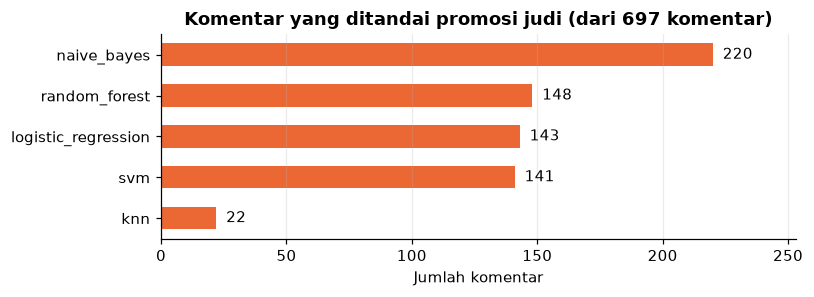

video_id,title,komentar_dinilai,naive_bayes,svm,random_forest,knn,logistic_regression
VXqMJqP7mvk,HP TERGILA yang dijual RESMI di INDONESIA! - Huawei Mate XT!,243,51,25,31,5,31
gRjWM8jPIPw,"MR. BOND, MOBIL ANDA SUDAH SIAP | ASTON MARTIN DB12",224,78,45,46,9,44
ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,230,91,71,71,8,68


In [12]:
singkat = lambda k: k.replace("predicted_label_", "")
jumlah = df[KOLOM_PREDIKSI].sum().rename(singkat).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh(jumlah.index, jumlah.values, color="#eb6834", height=0.55)
for i, v in enumerate(jumlah.values):
    ax.text(v, i, f"  {v:,}", va="center")
ax.set_xlim(0, max(jumlah.max() * 1.15, 1))
ax.set(title=f"Komentar yang ditandai promosi judi (dari {len(df):,} komentar)", xlabel="Jumlah komentar")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("outputs/prediksi_per_model.png", bbox_inches="tight")
plt.show()

ringkas_video = df.groupby(["video_id", "title"], dropna=False)[KOLOM_PREDIKSI].sum().rename(columns=singkat)
ringkas_video.insert(0, "komentar_dinilai", df.groupby(["video_id", "title"], dropna=False).size())
tampil(ringkas_video.reset_index(), "Tabel 3.5. Jumlah komentar yang ditandai promosi per video", "ringkasan_prediksi_per_video.csv", sembunyikan_index=True)

Komentar yang ditandai oleh lebih banyak model umumnya lebih layak diperiksa lebih dulu. Kolom `jumlah_model_setuju` hanya
untuk tampilan di bawah dan tidak disimpan di CSV.

In [13]:
df["jumlah_model_setuju"] = df[KOLOM_PREDIKSI].sum(axis=1)
tampil(df["jumlah_model_setuju"].value_counts().sort_index().rename_axis("Jumlah model yang menandai promosi").to_frame("Jumlah komentar"),
       "Tabel 3.6. Kesepakatan antar model")

tampil(df.sort_values("jumlah_model_setuju", ascending=False)[["video_id", "komentar", "jumlah_model_setuju"]].head(15),
       "Tabel 3.7. Komentar yang paling banyak ditandai promosi (perlu diperiksa manual)", sembunyikan_index=True)

,Jumlah komentar
Jumlah model yang menandai promosi,
0,465
1,75
2,17
3,12
4,111
5,17


video_id,komentar,jumlah_model_setuju
VXqMJqP7mvk,"𝗪𝗗 pertama lancar, 𝗪𝗗 kedua lancar… 𝗠𝗔𝗫𝗪𝗜𝗡𝗕𝗢𝗦 emang jagonya! 🔥",5
VXqMJqP7mvk,"𝗪𝗗 pertama lancar, 𝗪𝗗 kedua lancar… 𝗠𝗔𝗫𝗪𝗜𝗡𝗕𝗢𝗦 emang bikin ketagihan! 🔄",5
VXqMJqP7mvk,"𝗪𝗗 pertama lancar, 𝗪𝗗 kedua makin lancar. 𝗠𝗔𝗫𝗪𝗜𝗡𝗕𝗢𝗦 emang bikin ketagihan! 🔥",5
ufS5vDKnIhM,"📈 Pasti cuan, pasti happy! 𝑲𝑰𝑵𝑮𝟑𝟐𝟖 terbaik! 💥🎯",5
gRjWM8jPIPw,"Temen-temen gue pada pindah ke 𝙋𝙐𝙇𝘼𝙐𝙒𝙄𝙉, dan gue ngerti kenapanya.",5
gRjWM8jPIPw,"Dulu sering bosen, sekarang tiap hari rame gara-gara P͎U͎L͎A͎U͎W͎I͎N͎.",5
gRjWM8jPIPw,Jekp𝙤t K O I S L O T selalu bikin ketagihan! 🎯,5
gRjWM8jPIPw,"Sempet ga percaya, eh bener gua maxwin diGa ru da Ho-ki😎🔥",5
ufS5vDKnIhM,Transmisi mt tetap terbaik.,5
ufS5vDKnIhM,"Jakpot besar bikin aku makin percaya sama keberuntungan, cuma di 𝑲𝑰𝑵𝑮𝟑𝟐𝟖!",5
